In [37]:
import numpy as np

base = r"C:\Human Activity Detection\UCI HAR Dataset\UCI HAR Dataset"

x_train = np.loadtxt(base + r"\train\X_train.txt")
y_train = np.loadtxt(base + r"\train\y_train.txt", dtype=int)
subject_train = np.loadtxt(base + r"\train\subject_train.txt", dtype=int)

In [38]:
print("X:", x_train.shape)
print("y:", y_train.shape)
print("subjects:", subject_train.shape)

X: (7352, 561)
y: (7352,)
subjects: (7352,)


In [39]:
print(np.unique(y_train))
print(np.bincount(y_train)[1:])

[1 2 3 4 5 6]
[1226 1073  986 1286 1374 1407]


In [42]:
activity_names = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING",
}

for label, count in zip(np.unique(y_train), np.bincount(y_train)[1:]):
    print(label, activity_names[label], ",count:", count)

1 WALKING ,count: 1226
2 WALKING_UPSTAIRS ,count: 1073
3 WALKING_DOWNSTAIRS ,count: 986
4 SITTING ,count: 1286
5 STANDING ,count: 1374
6 LAYING ,count: 1407


In [43]:
print("Missing values:", np.isnan(x_train).sum())
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())
print("Subjects:", np.unique(subject_train))

Missing values: 0
Minimum: -1.0
Maximum: 1.0
Subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]


In [44]:
print("Subject shape:", subject_train.shape)
print("Unique subjects:", np.unique(subject_train))
print("Number of subjects:", len(np.unique(subject_train)))

Subject shape: (7352,)
Unique subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Number of subjects: 21


In [45]:
subject_ids, subject_counts = np.unique(
    subject_train,
    return_counts=True
)

for subject_id, count in zip(subject_ids, subject_counts):
    print(f"Subject {subject_id}: {count} samples")

Subject 1: 347 samples
Subject 3: 341 samples
Subject 5: 302 samples
Subject 6: 325 samples
Subject 7: 308 samples
Subject 8: 281 samples
Subject 11: 316 samples
Subject 14: 323 samples
Subject 15: 328 samples
Subject 16: 366 samples
Subject 17: 368 samples
Subject 19: 360 samples
Subject 21: 408 samples
Subject 22: 321 samples
Subject 23: 372 samples
Subject 25: 409 samples
Subject 26: 392 samples
Subject 27: 376 samples
Subject 28: 382 samples
Subject 29: 344 samples
Subject 30: 383 samples


In [46]:
print("Missing feature values:", np.isnan(x_train).sum())
print("Missing labels:", np.isnan(y_train).sum())
print("Missing subjects:", np.isnan(subject_train).sum())

Missing feature values: 0
Missing labels: 0
Missing subjects: 0


In [47]:
print("Minimum feature value:", x_train.min())
print("Maximum feature value:", x_train.max())

Minimum feature value: -1.0
Maximum feature value: 1.0


In [48]:
feature_std = np.std(x_train, axis=0)

print("Constant features:", np.sum(feature_std == 0))

Constant features: 0


In [49]:
x_test = np.loadtxt(
    base + r"\test\X_test.txt"
)

y_test = np.loadtxt(
    base + r"\test\y_test.txt",
    dtype=int
)

subject_test = np.loadtxt(
    base + r"\test\subject_test.txt",
    dtype=int
)

print("X_test:", x_test.shape)
print("y_test:", y_test.shape)
print("subject_test:", subject_test.shape)

X_test: (2947, 561)
y_test: (2947,)
subject_test: (2947,)


In [50]:
train_subjects = set(np.unique(subject_train))
test_subjects = set(np.unique(subject_test))

print("Overlapping subjects:", train_subjects.intersection(test_subjects))

Overlapping subjects: set()


In [51]:
validation_subjects = [18, 19, 20, 21]

validation_mask = np.isin(subject_train, validation_subjects)
training_mask = ~validation_mask

x_train_model = x_train[training_mask]
y_train_model = y_train[training_mask] - 1

x_val = x_train[validation_mask]
y_val = y_train[validation_mask] - 1

print(x_train_model.shape)
print(y_train_model.shape)
print(x_val.shape)
print(y_val.shape)

(6584, 561)
(6584,)
(768, 561)
(768,)


In [52]:
print(len(x_train_model) + len(x_val))
print(len(x_train))

7352
7352


In [65]:
!pip install tensorflow --default-timeout=1000


Defaulting to user installation because normal site-packages is not writeable
  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.85.1-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Usin


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\safii\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [66]:
import tensorflow as tf

tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(561,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(6, activation="softmax")
])

In [67]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [68]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        71,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,582 (314.77 KB)

 Trainable params: 80,582 (314.77 KB)

 Non-trainable params: 0 (0.00 B)

In [69]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    x_train_model,
    y_train_model,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6220 - loss: 0.8819 - val_accuracy: 0.8138 - val_loss: 0.4227
Epoch 2/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8524 - loss: 0.3624 - val_accuracy: 0.8451 - val_loss: 0.3589
Epoch 3/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8970 - loss: 0.2496 - val_accuracy: 0.8646 - val_loss: 0.3183
Epoch 4/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9146 - loss: 0.2095 - val_accuracy: 0.8867 - val_loss: 0.2732
Epoch 5/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9332 - loss: 0.1674 - val_accuracy: 0.8789 - val_loss: 0.2965
Epoch 6/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9414 - loss: 0.1505 - val_accuracy: 0.8997 - val_loss: 0.2518
Epoch 7/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9505 - loss: 0.1286 - val_accuracy: 0.8659 - val_loss: 0.3880
Epoch 8/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9557 - loss: 0.1144 - val_accuracy: 0.

In [70]:
best_val_accuracy = max(history.history["val_accuracy"])

print("Best validation accuracy:", best_val_accuracy)
print("Epochs completed:", len(history.history["loss"]))

Best validation accuracy: 0.9401041865348816
Epochs completed: 22


In [72]:
!pip install matplotlib 

Defaulting to user installation because normal site-packages is not writeable
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp313-cp313-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp313-cp313-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl (70 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
 


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\safii\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


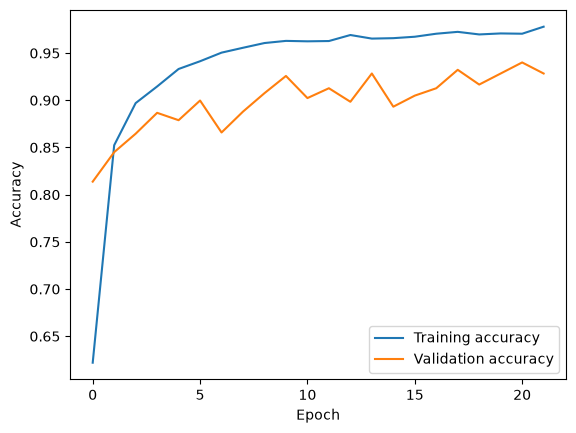

In [73]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

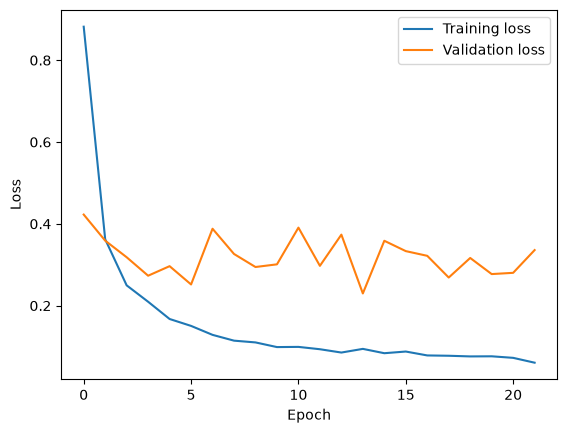

In [74]:
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [75]:
val_probabilities = model.predict(x_val)
val_predictions = np.argmax(val_probabilities, axis=1)

print(val_probabilities.shape)
print(val_predictions.shape)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
(768, 6)
(768,)


In [77]:
activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

sample_index = 0

print("Actual:", activity_names[y_val[sample_index]])
print("Predicted:", activity_names[val_predictions[sample_index]])
print("Confidence:", val_probabilities[sample_index].max())

Actual: STANDING
Predicted: STANDING
Confidence: 0.9913446


In [78]:
from sklearn.metrics import accuracy_score

validation_accuracy = accuracy_score(y_val, val_predictions)

print("Validation accuracy:", validation_accuracy)

Validation accuracy: 0.9283854166666666


In [79]:
print(np.unique(val_predictions))

[0 1 2 3 4 5]


In [80]:
confidence = val_probabilities.max(axis=1)

print("Average confidence:", confidence.mean())
print("Lowest confidence:", confidence.min())
print("Highest confidence:", confidence.max())

Average confidence: 0.9693077
Lowest confidence: 0.5055344
Highest confidence: 1.0


In [82]:
y_test_zero_based = y_test - 1

test_probabilities = model.predict(x_test)
test_predictions = np.argmax(test_probabilities, axis=1)

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test_zero_based, test_predictions)
precision = precision_score(
    y_test_zero_based,
    test_predictions,
    average="weighted"
)
recall = recall_score(
    y_test_zero_based,
    test_predictions,
    average="weighted"
)
f1 = f1_score(
    y_test_zero_based,
    test_predictions,
    average="weighted"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.9351883271123176
Precision: 0.9402620716944206
Recall: 0.9351883271123176
F1-score: 0.9352186194810905


In [85]:
!pip install seaborn


Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached pandas-3.1.1-cp313-cp313-win_amd64.whl.metadata (16 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
    ----------------------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\safii\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


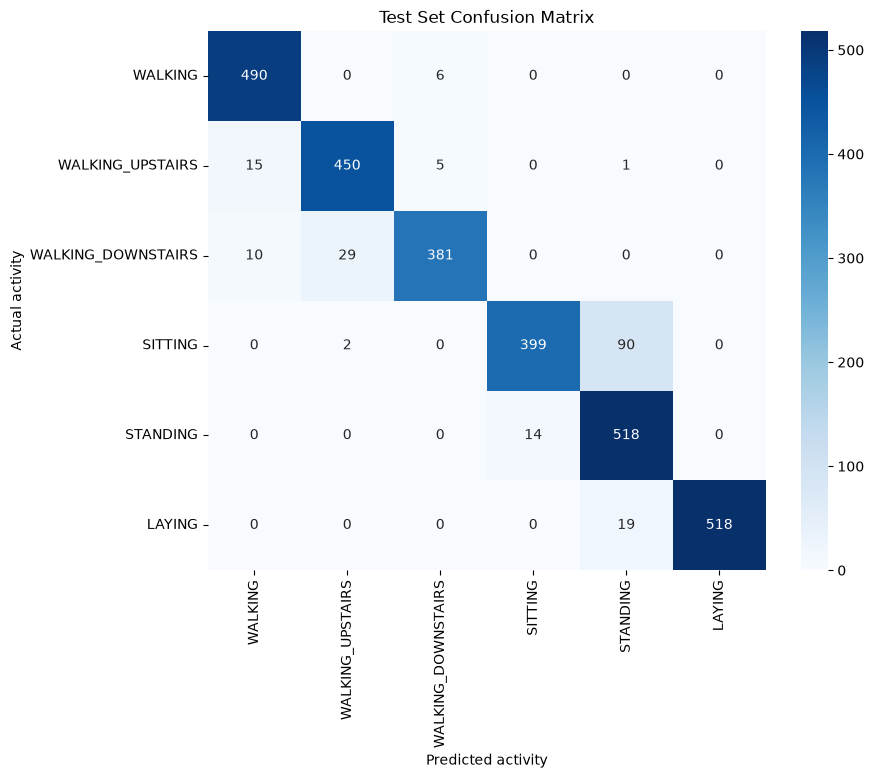

In [86]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_zero_based,
    test_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_names,
    yticklabels=activity_names
)

plt.xlabel("Predicted activity")
plt.ylabel("Actual activity")
plt.title("Test Set Confusion Matrix")
plt.show()

In [87]:
model.save("har_baseline.keras")

In [88]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("har_baseline.tflite", "wb") as file:
    file.write(tflite_model)

print("TFLite model size:", len(tflite_model), "bytes")

INFO:tensorflow:Assets written to: C:\Users\safii\AppData\Local\Temp\tmpr4d9pbvx\assets


INFO:tensorflow:Assets written to: C:\Users\safii\AppData\Local\Temp\tmpr4d9pbvx\assets


Saved artifact at 'C:\Users\safii\AppData\Local\Temp\tmpr4d9pbvx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 561), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2291772002896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772004240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772002128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772003856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772004048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772004624: TensorSpec(shape=(), dtype=tf.resource, name=None)
TFLite model size: 324520 bytes


In [89]:
interpreter = tf.lite.Interpreter(model_path="har_baseline.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(input_details)
print(output_details)

[{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([  1, 561], dtype=int32), 'shape_signature': array([ -1, 561], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]
[{'name': 'StatefulPartitionedCall_1:0', 'index': 10, 'shape': array([1, 6], dtype=int32), 'shape_signature': array([-1,  6], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]


C:\Users\safii\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [90]:
sample = x_test[0:1].astype(np.float32)

interpreter.set_tensor(
    input_details[0]["index"],
    sample
)

interpreter.invoke()

tflite_output = interpreter.get_tensor(
    output_details[0]["index"]
)

print(tflite_output)
print("Predicted class:", np.argmax(tflite_output, axis=1))
print("Expected class:", y_test_zero_based[0])

[[2.9255496e-06 8.1044846e-06 1.1876696e-06 7.5588124e-03 9.9242616e-01
  2.8251563e-06]]
Predicted class: [4]
Expected class: 4


In [91]:
tflite_predictions = []

for sample in x_test:
    sample = sample.reshape(1, 561).astype(np.float32)

    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    tflite_predictions.append(np.argmax(output[0]))

In [92]:
tflite_predictions = np.array(tflite_predictions)

In [93]:
tflite_accuracy = accuracy_score(
    y_test_zero_based,
    tflite_predictions
)

print("TFLite accuracy:", tflite_accuracy)

TFLite accuracy: 0.9351883271123176


In [94]:
print("Keras accuracy:", accuracy)
print("TFLite accuracy:", tflite_accuracy)
print("Difference:", accuracy - tflite_accuracy)

Keras accuracy: 0.9351883271123176
TFLite accuracy: 0.9351883271123176
Difference: 0.0


In [95]:
keras_predictions = np.argmax(test_probabilities, axis=1)

agreement = np.mean(
    keras_predictions == tflite_predictions
)

print("Keras/TFLite prediction agreement:", agreement)

Keras/TFLite prediction agreement: 1.0


In [96]:
import time

In [97]:
sample = x_test[0:1].astype(np.float32)

model.predict(sample, verbose=0)

interpreter.set_tensor(
    input_details[0]["index"],
    sample
)
interpreter.invoke()

In [98]:
repetitions = 100

start = time.perf_counter()

for _ in range(repetitions):
    model.predict(sample, verbose=0)

keras_elapsed = time.perf_counter() - start
keras_average_ms = (keras_elapsed / repetitions) * 1000

print("Keras average latency:", keras_average_ms, "ms")

Keras average latency: 77.68137299921364 ms


In [99]:
start = time.perf_counter()

for _ in range(repetitions):
    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]["index"])

tflite_elapsed = time.perf_counter() - start
tflite_average_ms = (tflite_elapsed / repetitions) * 1000

print("TFLite average latency:", tflite_average_ms, "ms")

TFLite average latency: 0.011170001234859228 ms


In [100]:
print("Keras latency:", keras_average_ms, "ms")
print("TFLite latency:", tflite_average_ms, "ms")
print("Speedup:", keras_average_ms / tflite_average_ms)

Keras latency: 77.68137299921364 ms
TFLite latency: 0.011170001234859228 ms
Speedup: 6954.464137102007


In [101]:
import os

keras_size_mb = os.path.getsize("har_baseline.keras") / (1024 ** 2)
tflite_size_mb = os.path.getsize("har_baseline.tflite") / (1024 ** 2)

print("Keras size:", keras_size_mb, "MB")
print("TFLite size:", tflite_size_mb, "MB")

Keras size: 0.9507818222045898 MB
TFLite size: 0.30948638916015625 MB


In [102]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

quantized_tflite_model = converter.convert()

with open("har_quantized.tflite", "wb") as file:
    file.write(quantized_tflite_model)

print("Quantized size:", len(quantized_tflite_model), "bytes")

INFO:tensorflow:Assets written to: C:\Users\safii\AppData\Local\Temp\tmpxs7vyqg7\assets


INFO:tensorflow:Assets written to: C:\Users\safii\AppData\Local\Temp\tmpxs7vyqg7\assets


Saved artifact at 'C:\Users\safii\AppData\Local\Temp\tmpxs7vyqg7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 561), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2291772002896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772004240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772002128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772003856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772004048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2291772004624: TensorSpec(shape=(), dtype=tf.resource, name=None)
Quantized size: 86912 bytes


In [103]:
quantized_interpreter = tf.lite.Interpreter(
    model_path="har_quantized.tflite"
)

quantized_interpreter.allocate_tensors()

print(quantized_interpreter.get_input_details())
print(quantized_interpreter.get_output_details())

[{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([  1, 561], dtype=int32), 'shape_signature': array([ -1, 561], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]
[{'name': 'StatefulPartitionedCall_1:0', 'index': 10, 'shape': array([1, 6], dtype=int32), 'shape_signature': array([-1,  6], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]


C:\Users\safii\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [104]:
quantized_interpreter = tf.lite.Interpreter(
    model_path="har_quantized.tflite"
)

quantized_interpreter.allocate_tensors()

quantized_input = quantized_interpreter.get_input_details()[0]
quantized_output = quantized_interpreter.get_output_details()[0]

quantized_predictions = []

for sample in x_test:
    sample = sample.reshape(1, 561).astype(np.float32)

    quantized_interpreter.set_tensor(
        quantized_input["index"],
        sample
    )

    quantized_interpreter.invoke()

    output = quantized_interpreter.get_tensor(
        quantized_output["index"]
    )

    quantized_predictions.append(np.argmax(output[0]))

quantized_predictions = np.array(quantized_predictions)

In [105]:
quantized_accuracy = accuracy_score(
    y_test_zero_based,
    quantized_predictions
)

print("Quantized TFLite accuracy:", quantized_accuracy)

Quantized TFLite accuracy: 0.9351883271123176


In [106]:
quantized_size_mb = os.path.getsize(
    "har_quantized.tflite"
) / (1024 ** 2)

print("Quantized TFLite size:", quantized_size_mb, "MB")

Quantized TFLite size: 0.0828857421875 MB


In [107]:
start = time.perf_counter()

for _ in range(repetitions):
    quantized_interpreter.set_tensor(
        quantized_input["index"],
        sample
    )
    quantized_interpreter.invoke()
    quantized_interpreter.get_tensor(
        quantized_output["index"]
    )

quantized_elapsed = time.perf_counter() - start
quantized_average_ms = (
    quantized_elapsed / repetitions
) * 1000

print("Quantized TFLite latency:", quantized_average_ms, "ms")

Quantized TFLite latency: 0.009254999458789825 ms


In [108]:
print("Model                  Size (MB)   Accuracy   Latency (ms)")
print("Keras                  ", keras_size_mb, accuracy, keras_average_ms)
print("TFLite float32         ", tflite_size_mb, tflite_accuracy, tflite_average_ms)
print("TFLite dynamic range   ", quantized_size_mb, quantized_accuracy, quantized_average_ms)

Model                  Size (MB)   Accuracy   Latency (ms)
Keras                   0.9507818222045898 0.9351883271123176 77.68137299921364
TFLite float32          0.30948638916015625 0.9351883271123176 0.011170001234859228
TFLite dynamic range    0.0828857421875 0.9351883271123176 0.009254999458789825


In [109]:
start = time.perf_counter()

for _ in range(repetitions):
    model(sample, training=False).numpy()

keras_direct_elapsed = time.perf_counter() - start
keras_direct_ms = keras_direct_elapsed / repetitions * 1000

print("Keras direct latency:", keras_direct_ms, "ms")

Keras direct latency: 3.8904179981909692 ms
